In [1]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator as IDG
import kagglehub
from sklearn.metrics import (accuracy_score,log_loss, classification_report,confusion_matrix,ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

Data Generation and Training Model

In [2]:
path = kagglehub.dataset_download("msambare/fer2013")

Using Colab cache for faster access to the 'fer2013' dataset.


In [3]:
train_dir = "/kaggle/input/fer2013/train"
val_dir = "/kaggle/input/fer2013/test"

num_train = 28709
num_val = 7178
batch_size = 64
num_epoch = 100

train_datagen = IDG(rescale=1./255,
              rotation_range=10,
              zoom_range=0.2,
              width_shift_range=0.1,
              height_shift_range=0.1,
              shear_range=0.2,
              horizontal_flip=True,
              fill_mode="nearest")

valid_datagen = IDG(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
        train_dir,
        target_size=(48,48),
        batch_size=batch_size,
        color_mode="grayscale",
        class_mode='categorical')

validation_generator = valid_datagen.flow_from_directory(
        val_dir,
        target_size=(48,48),
        batch_size=batch_size,
        color_mode="grayscale",
        class_mode='categorical',
        shuffle=False)

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [4]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(48,48,1)))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(7, activation='softmax'))
model.compile(loss='categorical_crossentropy',optimizer=Adam(learning_rate=0.0001),metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Train Model

In [5]:
model_info = model.fit(
        train_generator,
        epochs=num_epoch,
        validation_data=validation_generator)

Epoch 1/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 262s 557ms/step - accuracy: 0.2509 - loss: 1.8158 - val_accuracy: 0.2754 - val_loss: 1.7786
Epoch 2/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 80s 179ms/step - accuracy: 0.2882 - loss: 1.7460 - val_accuracy: 0.3589 - val_loss: 1.6640
Epoch 3/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 79s 175ms/step - accuracy: 0.3305 - loss: 1.6843 - val_accuracy: 0.3901 - val_loss: 1.5719
Epoch 4/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 78s 174ms/step - accuracy: 0.3558 - loss: 1.6372 - val_accuracy: 0.4299 - val_loss: 1.5236
Epoch 5/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 77s 173ms/step - accuracy: 0.3809 - loss: 1.5863 - val_accuracy: 0.4480 - val_loss: 1.4498
Epoch 6/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 78s 173ms/step - accuracy: 0.3985 - loss: 1.5495 - val_accuracy: 0.4675 - val_loss: 1.4033
Epoch 7/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 78s 173ms/step - accuracy: 0.4246 - loss: 1.4989 - val_accuracy: 0.4836 - val_loss: 1.3558
Epoch 8/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 77s 170ms/step - accuracy: 0.4373 

In [8]:
model.save_weights('emotion_weights.weights.h5')

Evaluate Model

113/113 ━━━━━━━━━━━━━━━━━━━━ 14s 118ms/step
Accuracy: 0.649902479799387
Loss: 0.9415511166747466
              precision    recall  f1-score   support

       angry     0.5320    0.6169    0.5713       958
     disgust     0.6923    0.4054    0.5114       111
        fear     0.5621    0.3623    0.4406      1024
       happy     0.8723    0.8551    0.8636      1774
     neutral     0.5292    0.7413    0.6176      1233
         sad     0.5616    0.4499    0.4996      1247
    surprise     0.7594    0.8014    0.7799       831

    accuracy                         0.6499      7178
   macro avg     0.6441    0.6046    0.6120      7178
weighted avg     0.6539    0.6499    0.6436      7178



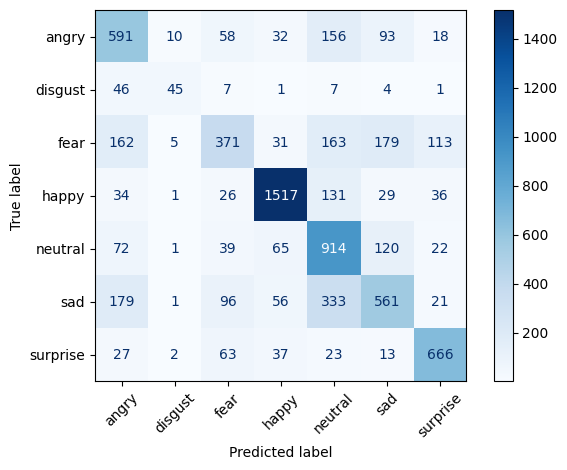

In [9]:
# Get model predictions
y_prob = model.predict(validation_generator, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Ground-truth labels (categorical one-hot encoded)
y_true = validation_generator.classes

class_names = list(validation_generator.class_indices.keys())

# Accuracy & Loss
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Loss:", log_loss(y_true, y_prob, labels=np.arange(y_prob.shape[1])))

# Precision, recall, F1-score for every emotion
print(classification_report(y_true,y_pred,labels=np.arange(len(class_names)),target_names=class_names,zero_division=0,digits=4))

# Confusion matrix
cm = confusion_matrix(y_true,y_pred,labels=np.arange(len(class_names)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()